# GRB2's SH3 domain, from Python

MaveScape's GRB2 example, run from a notebook: the published counts of an abundance selection of
every substitution in GRB2's SH3 domain, from the Human Domainome, opened, checked and scored in the
MaveScape window; the scores compared with those the authors deposited in MaveDB; and a figure made
and exported. Each step appears in the window as it runs and goes into the workspace's history, as
the person's own changes do.

**To run it**, start MaveScape with remote control and install the Python client, with pandas and
matplotlib for the tables and plots:

```sh
mavescape --remote-control
pip install ./clients/python pandas matplotlib
```

The client finds the running MaveScape by itself. The comparison downloads the published scores
from MaveDB once (about 100 KB); MaveScape keeps them in its cache. What the notebook writes goes
into a folder `grb2-sh3` beside it. The checks (`assert`) are what the project's CI checks when it
runs this notebook against a build of MaveScape.

The data: Beltran A, et al. Site-saturation mutagenesis of 500 human protein domains. *Nature*
2025. doi:10.1038/s41586-024-08370-4. MaveDB urn:mavedb:00000835-a-1 (CC0).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image

import mavescape

ms = mavescape.connect(client="GRB2 notebook")
out = Path("grb2-sh3").resolve()
out.mkdir(exist_ok=True)

## The example

`open_example` opens the bundled counts as a new workspace, with the design that says which column
is which sample (an input and an output in each of three replicates), and scores them with
MaveScape's defaults: Run 1.

In [2]:
opened = ms.open_example(id="grb2-sh3")
print(opened.message)

Opened the example "GRB2 SH3 domain (published)", scored with MaveScape's defaults. Showing qc. Which positions of the SH3 domain does the protein need to fold and stay abundant, and how sure are the scores?


## Checked before scoring

`check` checks a table as scoring would, without scoring: the variants' names against the target,
the design against the table's columns, the parameters against the design. Its readiness says
which analyses the data allow, and what each of the others would need.

In [3]:
checked = ms.check()
print(checked.message)
assert checked["valid"]
readiness = pd.DataFrame(checked["readiness"]["analyses"])
readiness[["group", "label", "status", "needs"]]

Valid: GRB2 SH3 domain (published): counts, 1121 rows (1121 names valid), with the design (two-population, 3 replicates of 6 samples).


,group,label,status,needs
0,Scoring,Log ratios of output to input (Enrich2),ready,[]
1,Scoring,DiMSum's fitness and error model,ready,[]
2,Normalization and scales,Scores relative to the wild type,ready,[]
3,Normalization and scales,Scores relative to the synonymous median,unavailable,[synonymous]
4,Normalization and scales,"Rescaled: nonsense 0, wild type 1",ready,[]
5,Normalization and scales,"Rescaled: synonymous 0, nonsense −1",unavailable,[synonymous]
6,Replicates,Replicates combined with the noise between them,ready,[]
7,Replicates,How far a score moves with one replicate left out,ready,[]
8,Conditions,Differential scores between conditions,unavailable,[conditions]
9,Quality control,Every sample has counts,ready,[]


## Quality control

Run 1's QC findings, one row each. One fails: the replicates differ about eleven times as much as
counting predicts.

In [4]:
findings = ms.qc_findings(run="Run 1").frame()
assert list(findings[findings.status == "fail"].id) == ["excess-variance"]
findings[["title", "status", "value"]]

,title,status,value
0,Every sample has counts,pass,"6 samples, each with counts"
1,Sequencing depth,pass,"lowest 264 reads per variant (Input, replicate 1)"
2,Low counts before selection,pass,up to 2.2% of input variants below 10 reads
3,Missing counts,pass,typical sample: 0.3% of variants missing
4,Missing after selection,pass,0 variants missing after selection; zeros are ...
5,Coverage of designed substitutions,pass,"100% (1117 of 1120; missense 1061/1064, nonsen..."
6,Replicate agreement,pass,lowest Pearson r 0.88 (3 pairs; Spearman 0.82)
7,Variance beyond counting (bottleneck),fail,11.4× the counting variance; DiMSum's terms up...
8,Outlier replicates,pass,largest 1.2× the others (rep3)
9,Separation of controls,pass,"AUC 1.000 (wild type median 0.00, nonsense -4.59)"


The Domainome's own analysis found why: a bottleneck at the input, too few cells carrying the
library into selection for each variant's share to be what its reads say. The finding is
acknowledged with that reason.
A script's changes apply as the person's do (an AI agent's would wait for the person), so it
holds at once; the reason goes into the history, the methods and any figure of the finding.

In [5]:
acknowledged = ms.acknowledge_finding(run="Run 1", finding="excess-variance", reason="The input bottleneck the Domainome's own analysis found")
print(acknowledged.message)

Acknowledged "Variance beyond counting (bottleneck)" (fail): The input bottleneck the Domainome's own analysis found. Its status is unchanged; the reason goes into the history, the methods and the QC exports.


## The scores as a data frame

`scores` gives a run's variants with the columns of its scores export: the score, its SE and 95%
interval, each replicate's score, the variant's class and status. Numbers are numbers, and NA is
missing.

In [6]:
run1 = ms.scores(run="Run 1", limit=0).frame()
print(f"{len(run1)} variants")
run1.groupby("variant_class")["score"].describe()[["count", "50%", "min", "max"]]

1121 variants


,count,50%,min,max
variant_class,,,,
missense,1061.0,-0.795537,-6.226211,1.144465
nonsense,56.0,-4.590260,-5.582576,-2.083586
wild type,1.0,0.000000,0.000000,0.000000


Each position's median missense score, on GRB2's own numbering (the design's offset places the
domain at residues 159–214 of P62993). The positions that tolerate nothing are buried in the fold.

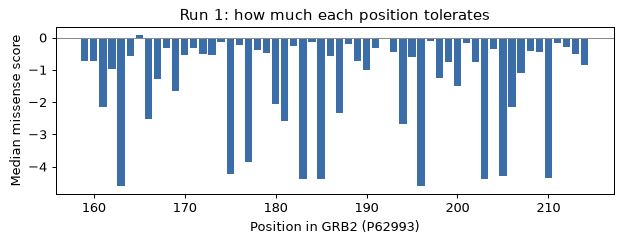

position
163   -4.60
196   -4.60
203   -4.40
183   -4.39
Name: score, dtype: float64

In [7]:
offset = ms.provenance(run="Run 1")["inputs"]["design"]["targets"][0]["offset"]
missense = run1[run1.variant_class == "missense"].copy()
missense["position"] = missense.hgvs_pro.str.extract(r"p\.[A-Za-z]{3}(\d+)", expand=False).astype(int) + offset
by_position = missense.groupby("position")["score"].median()

fig, ax = plt.subplots(figsize=(8, 2.4), dpi=90)
ax.bar(by_position.index, by_position.values, color="#3b6ea8")
ax.axhline(0, color="#888", lw=0.8)
ax.set(xlabel="Position in GRB2 (P62993)", ylabel="Median missense score", title="Run 1: how much each position tolerates")
plt.show()

least = by_position.nsmallest(4)
assert set(least.index) == {163, 183, 196, 203}
least.round(2)

## Scored again, as the authors scored it

The Domainome scored its counts with DiMSum. The DiMSum-compatible preset fits DiMSum's error model,
whose terms say where the variance beyond counting enters: each input and output's multiple of
counting noise.

In [8]:
run2 = ms.score(preset="dimsum")
print(run2.message)
terms = pd.DataFrame(run2["dimsum"]).set_index("replicate")[["input", "output"]]
assert (terms.input > 4 * terms.output).all()
terms

Run 2: 1108 of 1121 variants scored (DiMSum-compatible). DiMSum's multiplicative terms: Replicate 1 input 30.67, output 1.678; Replicate 2 input 19.87, output 2.71; Replicate 3 input 37.62, output 5.249.


,input,output
replicate,,
Replicate 1,30.67,1.678
Replicate 2,19.87,2.710
Replicate 3,37.62,5.249


## Against the published scores

`compare` takes a MaveDB score set by its URN: MaveScape fetches it and keeps it beside the
workspace without opening it. The authors rescaled their scores, so each side is rescaled by its own
anchors (nonsense median 0, wild type 1) for Lin's concordance and Bland–Altman. Both come from one
experiment, so the agreement measures the analyses, not the experiment's reproducibility.

In [9]:
URN = "urn:mavedb:00000835-a-1"
rows = []
for run in ["Run 1", "Run 2"]:
    s = ms.compare(a=run, b=URN, scale="nonsense-wt")["statistics"]
    rows.append({"run": run, "variants": s["n"], "Pearson's r": s["pearson"]["r"], "Lin's concordance": s["concordance"]["ccc"], "bias": s["blandAltman"]["bias"]})
agreement = pd.DataFrame(rows).set_index("run").round(3)
assert (agreement["Pearson's r"] > 0.99).all() and agreement.loc["Run 1", "Lin's concordance"] > 0.99
agreement

,variants,Pearson's r,Lin's concordance,bias
run,,,,
Run 1,1107,0.997,0.996,0.009
Run 2,1107,0.994,0.994,-0.003


The variants compared, from the comparison's export: each side's score as scored and as compared.

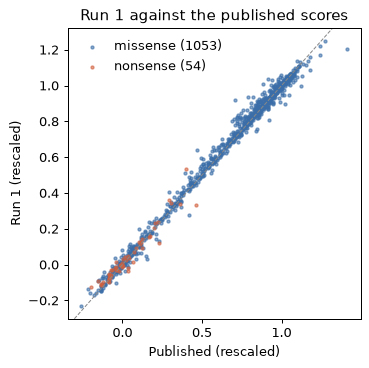

In [10]:
ms.compare(a="Run 1", b=URN, scale="nonsense-wt")
ms.export("comparison", path=str(out / "run1-vs-published.csv"), overwrite=True)
pairs = pd.read_csv(out / "run1-vs-published.csv")

fig, ax = plt.subplots(figsize=(4.2, 4.2), dpi=90)
for kind, color in [("missense", "#3b6ea8"), ("nonsense", "#d1603d")]:
    some = pairs[pairs["class"] == kind]
    ax.scatter(some.compared_b, some.compared_a, s=6, alpha=0.6, color=color, label=f"{kind} ({len(some)})")
ax.axline((0, 0), slope=1, color="#888", lw=0.8, ls="--")
ax.set(xlabel="Published (rescaled)", ylabel="Run 1 (rescaled)", title="Run 1 against the published scores")
ax.legend(frameon=False)
plt.show()

## A figure

A figure made in the window: Run 1's map, its agreement with the published scores and the
bottleneck behind every SE, on a page of a journal's double column. `figures` checks it (no text
too small, no map too narrow) and describes it in words; exported as PDF and PNG, each file carries
its manifest: what each panel shows and was drawn from, Run 1 by its output's SHA-256 and the
acknowledgement's reason among them.

GRB2 SH3, 174 × 180 mm, 3 panels. Panel A: Variant-effect map of GRB2 SH3 domain: 56 positions by 21 substitutions (the 20 amino acids and stop), 1120 designed. 1026 scored, 91 scored with low confidence, 0 filtered, 3 missing. Positions least tolerant of substitution (lowest median score): G38 (196 in the reference) -4.57, A5 (163 in the reference) -4.56, I25 (183 in the reference) -4.46, G45 (20 …


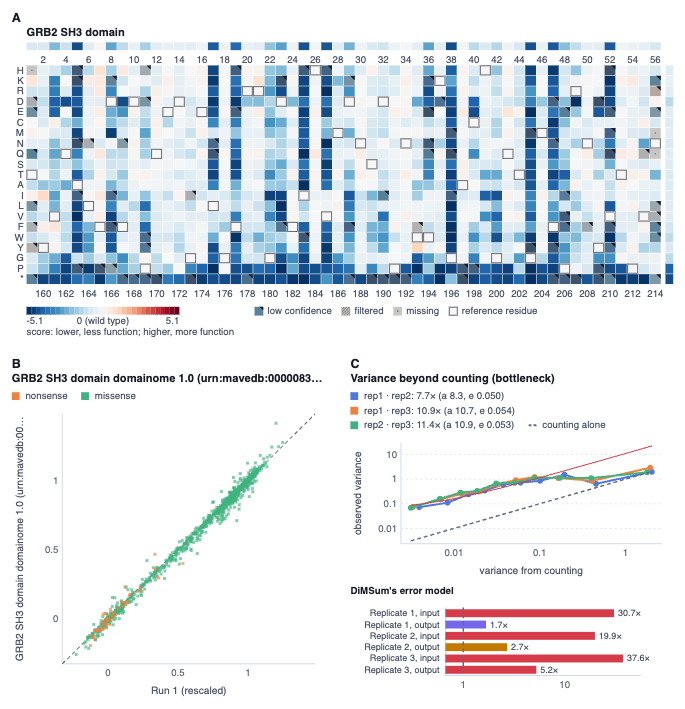

In [11]:
name = "GRB2 SH3"
ms.create_figure(name=name, size="double", height_mm=180)
ms.add_figure_panel(figure=name, kind="map", run="Run 1", x_mm=3, y_mm=3, width_mm=168, height_mm=84)
ms.add_figure_panel(figure=name, kind="compare", a="Run 1", b=URN, scale="nonsense-wt", plot="agreement", x_mm=3, y_mm=91, width_mm=80, height_mm=86)
ms.add_figure_panel(figure=name, kind="qc", subject="Run 1", finding="excess-variance", x_mm=89, y_mm=91, width_mm=82, height_mm=86)
for kind in ["pdf", "png"]:
    ms.export_figure(figure=name, path=str(out / f"grb2-sh3.{kind}"), overwrite=True)

page = ms.figures(figure=name, image=True, dpi=100)
assert not page["figures"][0]["notes"]
print(page["figures"][0]["description"][:400], "…")
Image(data=page.images()[0]["png"], width=640)

The workspace keeps all of it: the runs, the acknowledgement, the comparison's score set beside the
map, the figure. In the window, Report gives the methods of the whole analysis, with references.